In [33]:
import kagglehub
import os


# Download latest version
path = kagglehub.dataset_download("abdullahcetin/mirichoi0218insurance")
print("Path to dataset files:", path)
print(os.listdir(path))
path += "/insurance.csv"
print(path)

Path to dataset files: C:\Users\sadan\.cache\kagglehub\datasets\abdullahcetin\mirichoi0218insurance\versions\1
['insurance.csv']
C:\Users\sadan\.cache\kagglehub\datasets\abdullahcetin\mirichoi0218insurance\versions\1/insurance.csv


## EDA

In [34]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [35]:
df = pd.read_csv(path)

### Basic Data Audit

In [36]:
print(df.head())
print(df.info())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB
None


**Inference**
1. There are no null values
2. age, bmi, children are numerical data, sex, smoker, region are categorical and target is charges


### Check duplicated

In [37]:
print("No of rows duplicated: ",df.duplicated().sum())
print("No of rows before removing duplicate", len(df))
df = df.drop_duplicates()
print("No of rows before removing duplicate", len(df))

No of rows duplicated:  1
No of rows before removing duplicate 1338
No of rows before removing duplicate 1337


## Model training using pipeline

In [38]:
from sklearn.compose import ColumnTransformer

In [ ]:
from sklearn.linear_model import Ridge, Lasso, LinearRegression, ElasticNet
from matplotlib import transforms
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=44)

num_feature = [ "age", "bmi", "children" ]
cat_feature = ["sex", "region", "smoker"]

preprocessor = ColumnTransformer(
    transformers = [
        (
            "num",
            StandardScaler(),
            num_feature
            
        ),
        (
            "cat",
            OneHotEncoder(drop="first", handle_unknown='ignore'),
            cat_feature
        ),
        
    ]
)

r_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor), ("regressor", Ridge())]
)

In [ ]:
from sklearn.linear_model import LinearRegression
# CV
param_grid = [
    {
        "regressor": [LinearRegression()]
    },
    {
        "regressor": [Ridge()],
        "regressor__alpha" : [0.01, 0.1, 1.0, 10.0 , 20.0, 25.0, 100.0]
    },
    {
        "regressor": [Lasso()],
        "regressor__alpha" : [0.01, 0.1, 1.0, 10.0 , 20.0, 25.0, 100.0]
    },
    {
        "regressor": [ElasticNet()],
        "regressor__alpha" : [0.01, 0.1, 1.0, 10.0 , 20.0, 25.0, 100.0]
    }
]
grid_search = GridSearchCV(
    estimator=r_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring= {
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
    },
    n_jobs=-1,
    refit="rmse"
)

grid_search.fit(X_train, y_train)
print('--- Best Model Found ---')
print(grid_search.best_estimator_)
print(f'Best Hyperparameters: {grid_search.best_params_}')
print(f'Best CV RMSE: {-grid_search.best_score_:.4f}\n')

--- Best Model Found ---
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['sex', 'region',
                                                   'smoker'])])),
                ('regressor', Lasso(alpha=25.0))])
Best Hyperparameters: {'regressor': Lasso(), 'regressor__alpha': 25.0}
Best CV RMSE: 6200.0436



In [41]:
results_df = pd.DataFrame(grid_search.cv_results_)
results_df['rmse'] = np.sqrt(-results_df['mean_test_rmse'])
results_df['r2'] = results_df['mean_test_r2']
summary_df = results_df[['params', 'rmse', 'r2']].sort_values(by='rmse')
summary_df

,params,rmse,r2
13,"{'regressor': Lasso(), 'regressor__alpha': 25.0}",78.740356,0.737977
12,"{'regressor': Lasso(), 'regressor__alpha': 20.0}",78.741579,0.737950
11,"{'regressor': Lasso(), 'regressor__alpha': 10.0}",78.745643,0.737875
10,"{'regressor': Lasso(), 'regressor__alpha': 1.0}",78.752216,0.737765
2,"{'regressor': Ridge(), 'regressor__alpha': 0.1}",78.752945,0.737754
3,"{'regressor': Ridge(), 'regressor__alpha': 1.0}",78.753031,0.737764
9,"{'regressor': Lasso(), 'regressor__alpha': 0.1}",78.753096,0.737751
1,"{'regressor': Ridge(), 'regressor__alpha': 0.01}",78.753169,0.737750
8,"{'regressor': Lasso(), 'regressor__alpha': 0.01}",78.753186,0.737750
0,{'regressor': LinearRegression()},78.753197,0.737750


## Predict

In [42]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# 3. Evaluate Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'MAE: {mae}')
print(f'RMSE: {mse}')
print(f'R² Score: {r2}')

MAE: 3926.2491855409994
RMSE: 30652951.234289717
R² Score: 0.7816367691025441


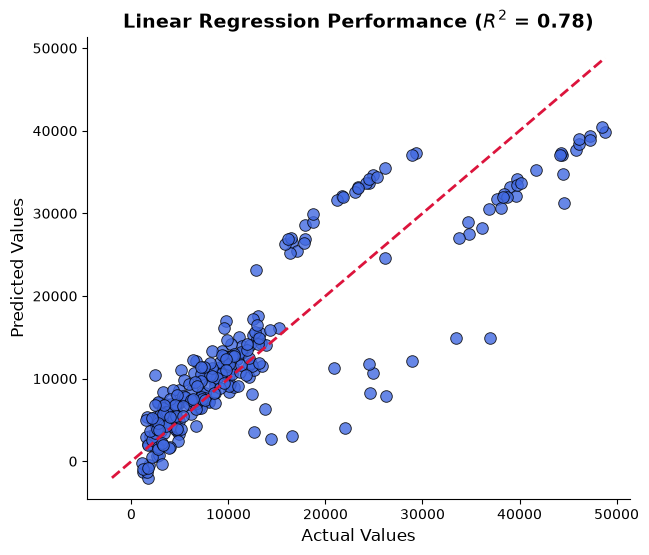

In [44]:
# 3. Create the Seaborn Plot
plt.figure(figsize=(7, 6))
# Use seaborn scatterplot (axes-level function supports 'ax=ax')
sns.scatterplot(
    x=y_test, 
    y=y_pred, 
    color='royalblue', 
    alpha=0.8, 
    edgecolor='k', 
    s=70
)

# Plot the ideal 45-degree reference line (y = x)
min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='crimson', linestyle='--', linewidth=2, label='Ideal Fit (y=x)')

# Set labels and title using standard matplotlib axes methods
plt.xlabel('Actual Values', fontsize=12)
plt.ylabel('Predicted Values', fontsize=12)
plt.title(f'Linear Regression Performance ($R^2$ = {r2:.2f})', fontsize=14, fontweight='bold')

# Add a text box displaying the metrics
sns.despine() # Removes top and right spines for a cleaner Seaborn aesthetic
